John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ─────────────────────

Load data

In [2]:
MODEL_TYPE <- "Top 5 Classes All songs since last own song"

data_list <- list()

# TO RUN MODEL ON ALL 11 FOCAL MALES:
folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    data_list <- append(data_list, list(read_csv(file)))
}

# # TO RUN MODEL ON 1 FOCAL MALE:
# file_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id\\YKY_song_type_id_frequency.csv" # TODO: Set file path to data for desired focal male
# data_list <- append(data_list, list(read_csv(file_path)))

Rows: 2169 Columns: 363
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (360): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 556 Columns: 365
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (362): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1033 Columns: 365
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (362): UST, time

In [3]:
# A lookup table to easily access IDs /ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

In [4]:
focal_ids <- list()
for (i in seq_along(data_list)) {
    id <- data_list[[i]] %>% pull(ID) %>% unique()
    # print(id)
    focal_ids[[id]] <- id
}
# focal_ids <- list("YKY")
names(data_list) <- focal_ids
# names(data_list) <- "YKY"

In [5]:
map(data_list, ~ head(.x, 3))

ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO,25,2022-05-13 05:24:14,-1935.691,NA,NA,NA,NA,NA,NA,⋯,1,1,1,5,5,5,6,6,6,5
DgTbO,20,2022-05-13 05:24:40,-1909.821,NA,NA,NA,NA,NA,NA,⋯,0,0,0,5,5,5,6,6,6,5
DgTbO,1,2022-05-13 05:24:48,-1901.666,NA,NA,NA,NA,NA,NA,⋯,0,0,0,5,5,5,6,6,6,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KLgK,0,2022-05-19 05:11:00,-2609.898,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
KLgK,0,2022-05-19 05:15:31,-2338.552,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
KLgK,0,2022-05-19 05:16:36,-2273.861,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number


In [6]:
# In data (training AND testing), how many of each song type for the focal male?

N <- 5
for (id in focal_ids) {
    cat("All song types for", id, ':\n')
    n_ust <- data_list[[id]] %>%
        group_by(UST) %>%
        summarize(n = n()) %>%
        mutate(percent = 100*n/nrow(data_list[[id]])) %>%
        arrange(desc(percent))
    print(n_ust)
    # Select only rows where class is one of top 5 songs
    top_n_ust <- n_ust %>% slice(0:N) %>% pull(UST)
    data_list[[id]] <- data_list[[id]] %>% filter(UST %in% top_n_ust)
}


All song types for DgTbO :
# A tibble: 29 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1    33   399   18.4 
 2    10   286   13.2 
 3    20   256   11.8 
 4     7   218   10.1 
 5     8   214    9.87
 6   153   176    8.11
 7     1   149    6.87
 8    12   102    4.70
 9    11   101    4.66
10    32    80    3.69
# ℹ 19 more rows
All song types for KLgK :
# A tibble: 20 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1     4    77  13.8  
 2    10    57  10.3  
 3     8    48   8.63 
 4    13    45   8.09 
 5     0    40   7.19 
 6     1    38   6.83 
 7    57    36   6.47 
 8    55    30   5.40 
 9    56    28   5.04 
10     5    27   4.86 
11    15    26   4.68 
12    12    22   3.96 
13    14    22   3.96 
14     9    18   3.24 
15    11    17   3.06 
16    58    11   1.98 
17     6     7   1.26 
18     3     3   0.540
19     7     2   0.360
20    59     2   0.360
All song types for KRDg :
# A tibble: 27 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1     9   135   13

In [7]:
data_list %>% map(~ head(.x, 3))
# map(data_list, ~ head(.x, 3))

ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO,20,2022-05-13 05:24:40,-1909.821,NA,NA,NA,NA,NA,NA,⋯,0,0,0,5,5,5,6,6,6,5
DgTbO,33,2022-05-13 05:25:09,-1880.963,NA,NA,NA,NA,NA,NA,⋯,25,25,25,0,0,0,6,6,6,5
DgTbO,8,2022-05-13 05:25:18,-1871.335,NA,NA,NA,NA,NA,NA,⋯,20,20,20,1,1,1,6,6,6,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KLgK,0,2022-05-19 05:11:00,-2609.898,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
KLgK,0,2022-05-19 05:15:31,-2338.552,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
KLgK,0,2022-05-19 05:16:36,-2273.861,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number


In [8]:
# Set data types and select input columns
for (i in seq_along(data_list) ){
    focal_male_number <- data_list[[i]] %>% pull(male_number) %>% unique()
    data_list[[i]] <- data_list[[i]] %>% 
        mutate(across(contains("UST"), ~ as.factor(.x)),
            # across(contains("ust"), ~ as.integer(.x)), 
            does_it_match = as.factor(does_it_match),
            number_of_matches = as.integer(number_of_matches)) %>%
        select(
            # Response
            "UST",

            # All neighbours' songs since last own song
            contains("n_ust_"),
            -contains("window"), # Don't include the # ust columns that use a time window
            # Own song history (song types)
            sprintf("M%i_1_last_UST", focal_male_number),
            sprintf("M%i_2_last_UST", focal_male_number),
            # sprintf("M%i_3_last_UST", focal_male_number),

            # Own song history (time since last songs)
            sprintf("time_since_M%i_1_last_song", focal_male_number),
            sprintf("time_since_M%i_2_last_song", focal_male_number),        
            # sprintf("time_since_M%i_3_last_song", focal_male_number)
        )  %>%
        drop_na() # drop any row containing at least one NA value
}


In [9]:
for (i in seq_along(data_list) ){
    print(focal_ids[i])
    cat("Columns:",length(data_list[[i]]), "Rows:", nrow(data_list[[i]]))
    print(glimpse(data_list[[i]]))
}

$DgTbO
[1] "DgTbO"

Columns: 75 Rows: 1362Rows: 1,362
Columns: 75
$ UST                       <fct> 33, 8, 33, 20, 7, 10, 33, 33, 33, 20, 33, 8,…
$ n_ust_1                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_3                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_4                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_5                   <fct> 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,…
$ n_ust_6                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_7                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_8                   <fct> 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,…
$ n_ust_9                   <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_10                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,…
$ n_ust_11                  <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_12                  <fct> 0, 0, 0, 0, 0, 0, 0,

In [10]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

In [11]:
models_list <- list()
training_datasets <- list()
testing_datasets <- list()

# for (i in seq_along(data_list)) {
for (id in focal_ids) {
    data <- data_list[[id]]

    # Check if we have enough data (e.g., at least 10-20 rows)
    if (nrow(data) < 10) {
        warning(paste("Skipping ID", id, "because it only has", nrow(data), "rows."))
        next
    }

    # train test split
    train_test_split <- initial_split(data, prop = 0.7, strata=UST)

    train_data <- train_test_split %>% training()
    training_datasets[[id]] <- train_data
    test_data <- train_test_split %>% testing()
    testing_datasets[[id]] <- test_data

    # In training data, how many of each song type?
    n_ust <- train_data %>%
        group_by(UST) %>%
        summarize(n = n()) %>%
        mutate(percent = 100*n/nrow(train_data)) %>%
        arrange(percent)
    n_ust

    # use v-fold cross validation to assess model accuracy
    v <- 5
    train_vfold <- vfold_cv(train_data, v=v, strata = UST)



    # Data preprocessing using a recipe
    recipe <- recipe(UST ~ ., data = train_data) %>%
        step_scale(all_numeric()) %>% # scale all numeric predictors
        step_center(all_numeric()) # center all numeric predictors


    model_tuning <- workflow() %>%
        add_recipe(recipe) %>%
        add_model(model_tuning_spec) %>%

            tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
            # fit(data = train_data) # to train on whole train set with no validation set

    model_tuning

    # Accuracies listed use 5-fold cross validation
    model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
    model_tuning_accuracies

    # plot accuracies of all values of hyperparameters

    ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
        geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
        geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
        labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
        theme(text = element_text(size=20)) +
        scale_fill_gradient(low="white", high="red")

    # Print best hyperparameter values
    best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
    print("Best hyperparameters: (mtry, min_n)")
    print(best_params)

    # retrain model on best parameters
    best_params <- model_tuning %>%
    select_best()
    print("Best Parameters:")
    print(best_params)

    model <- workflow() %>%
        add_recipe(recipe) %>%
        add_model(model_tuning_spec) %>%
        finalize_workflow(best_params) %>%
        # fit_resamples(resamples = train_vfold) # for v-fold cross validation
        fit(data = train_data) # to train on whole train set with no validation set

    models_list[[id]] <- model

}
names(models_list) <- focal_ids
names(training_datasets) <- focal_ids
names(testing_datasets) <- focal_ids

→ A | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, and those levels will be removed from the
               averaged result.
               Note that the following number of true events actually occurred for each
               problematic event level:
               '7': 31, '8': 30, '10': 40

→ B | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, and those levels will be removed from the
               averaged result.
               Note that the following number of true events actually occurred for each
               problematic event level:
               '7': 31, '8': 30

There were issues with some computations   A: x3   B: x2

There were issues with some computations   A: x8   B

[1] "Best hyperparameters: (mtry, min_n)"
15 
 4 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    16    10 pre0_mod18_post0


→ A | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, and those levels will be removed from the
               averaged result.
               Note that the following number of true events actually occurred for each
               problematic event level:
               '8': 7, '13': 6

→ B | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, and those levels will be removed from the
               averaged result.
               Note that the following number of true events actually occurred for each
               problematic event level:
               '8': 7, '10': 8, '13': 6

There were issues with some computations   A: x1   B: x4

→ C | warning: While computing multiclass `precision()`

[1] "Best hyperparameters: (mtry, min_n)"
20 
 4 


... (30 outputs left out)

Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    20     5 pre0_mod22_post0
[1] "Best hyperparameters: (mtry, min_n)"
15 
20 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    20    20 pre0_mod25_post0


In [12]:
models <- tibble(
    id = focal_ids,
    model = models_list,
    train_data = list(training_datasets),
    test_data = list(testing_datasets)
)

DgTbO 5 6 


Saving 6.67 x 6.67 in image


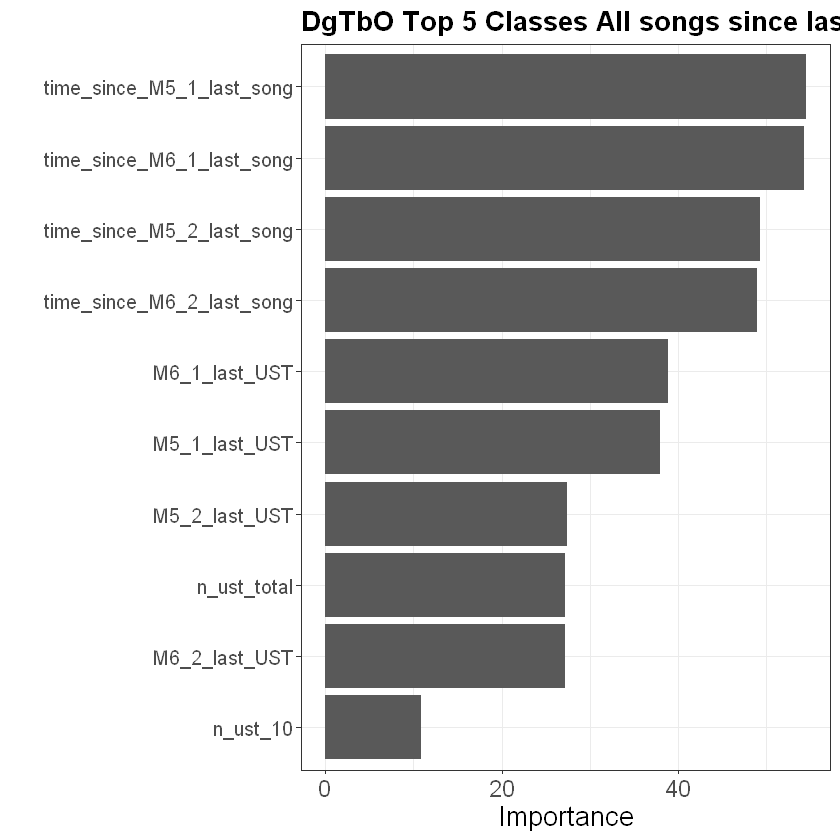

KLgK 5 


Saving 6.67 x 6.67 in image


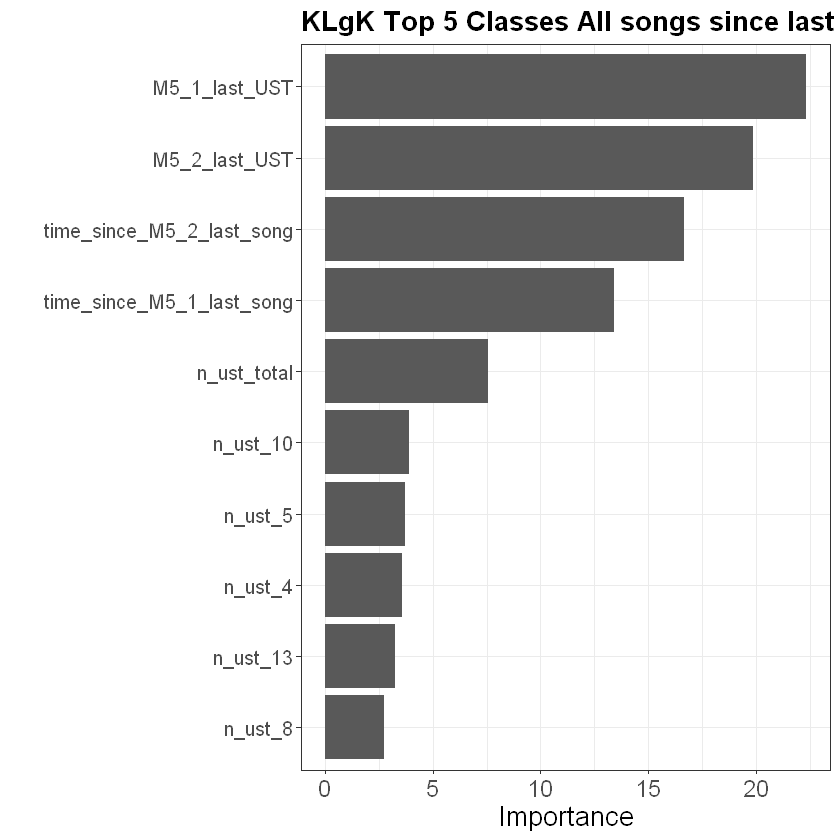

KRDg 2 


Saving 6.67 x 6.67 in image


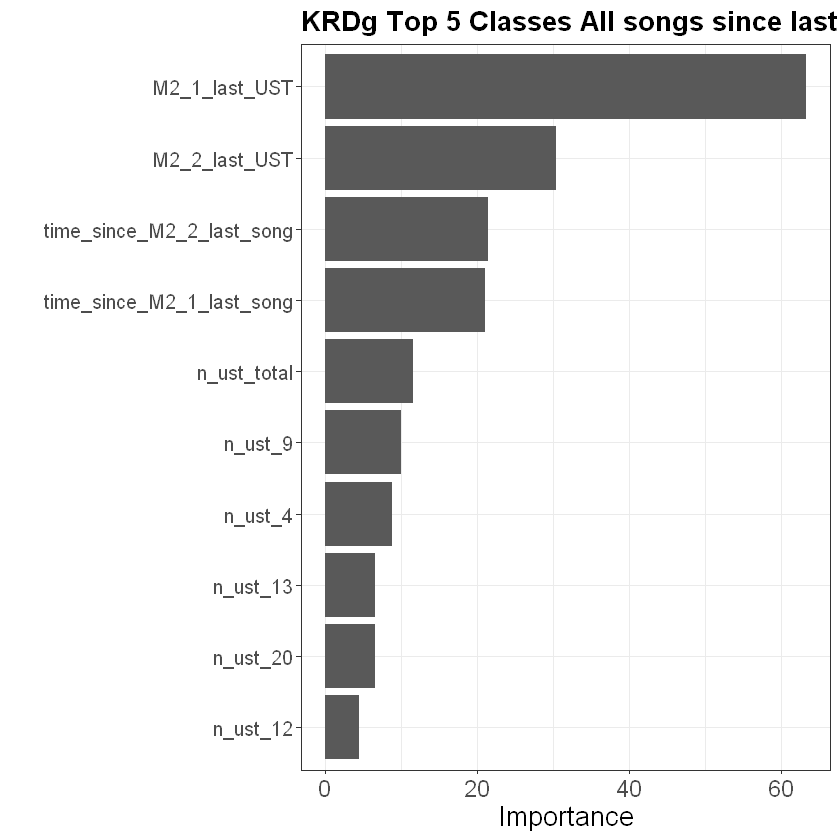

LbOW 1 


Saving 6.67 x 6.67 in image


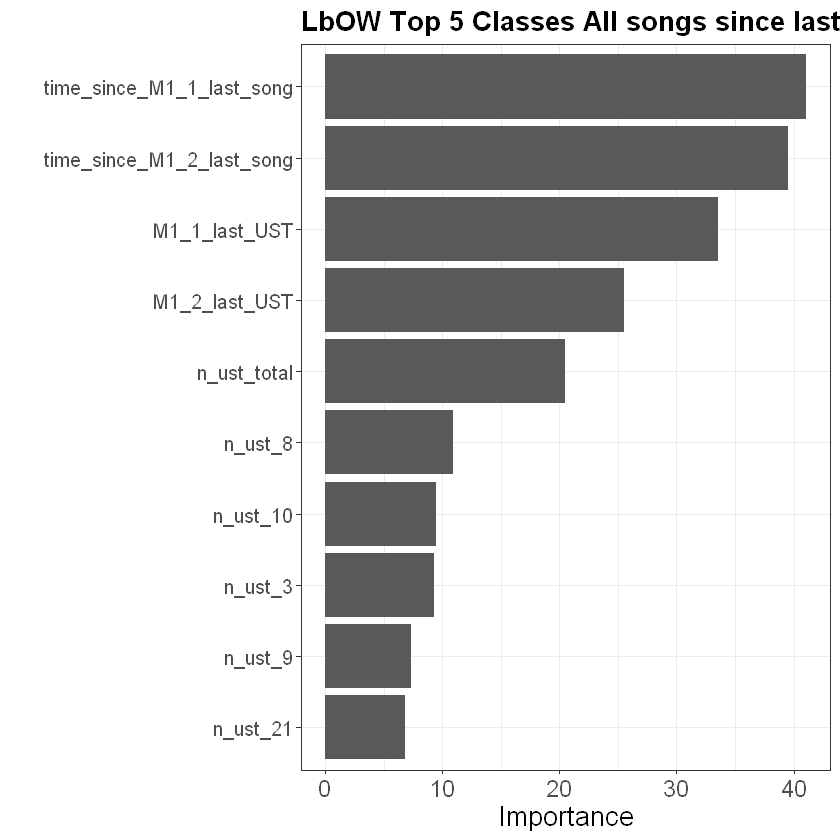

OPR 3 


Saving 6.67 x 6.67 in image


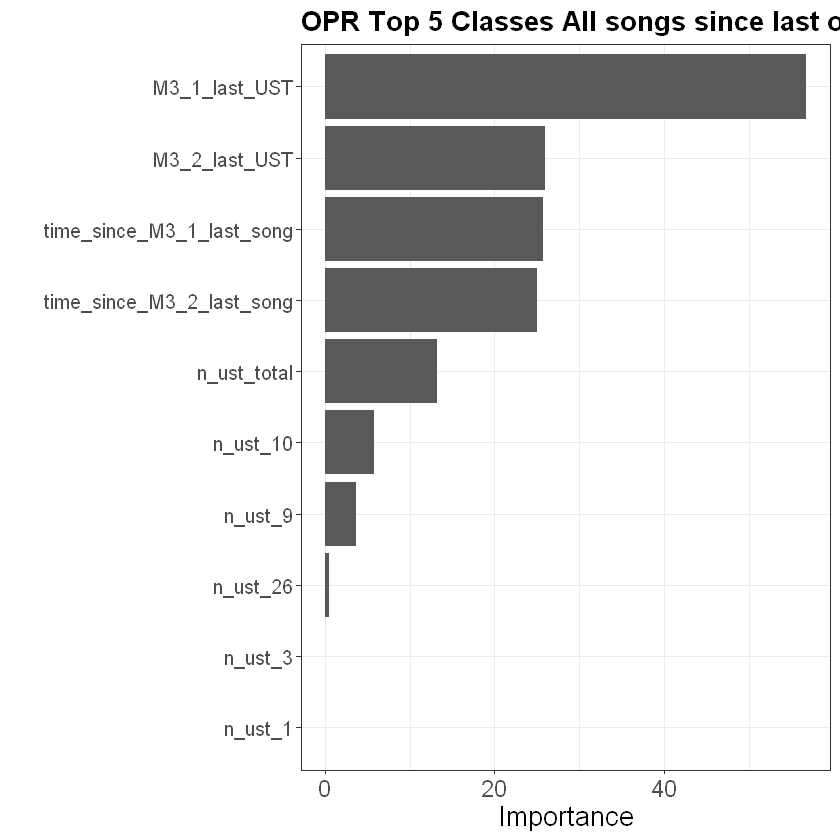

RbDgY 2 


Saving 6.67 x 6.67 in image


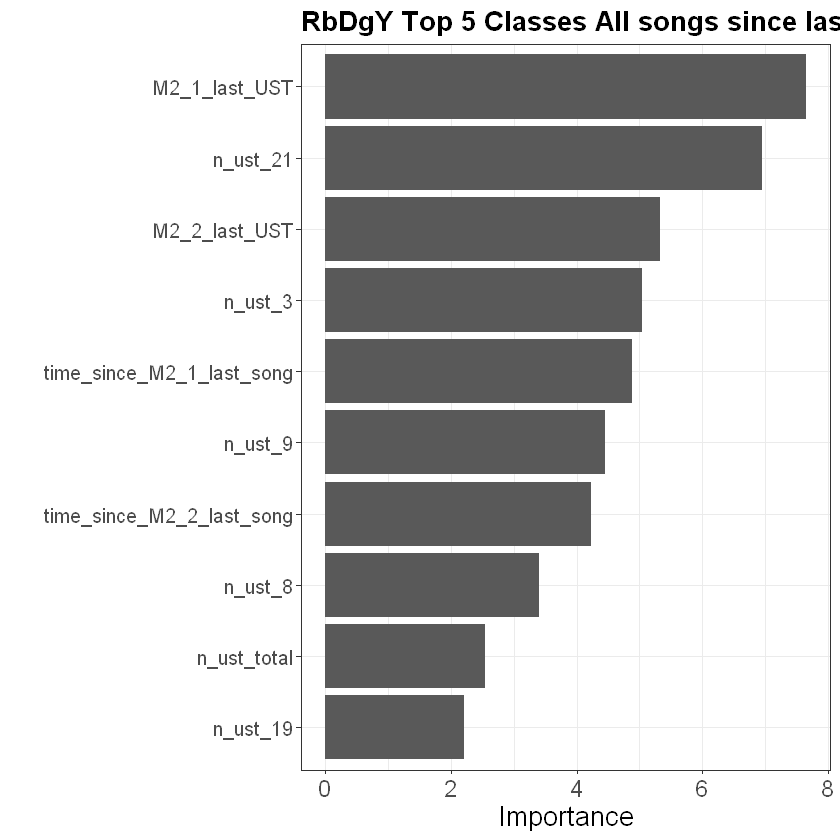

RRO 6 


Saving 6.67 x 6.67 in image


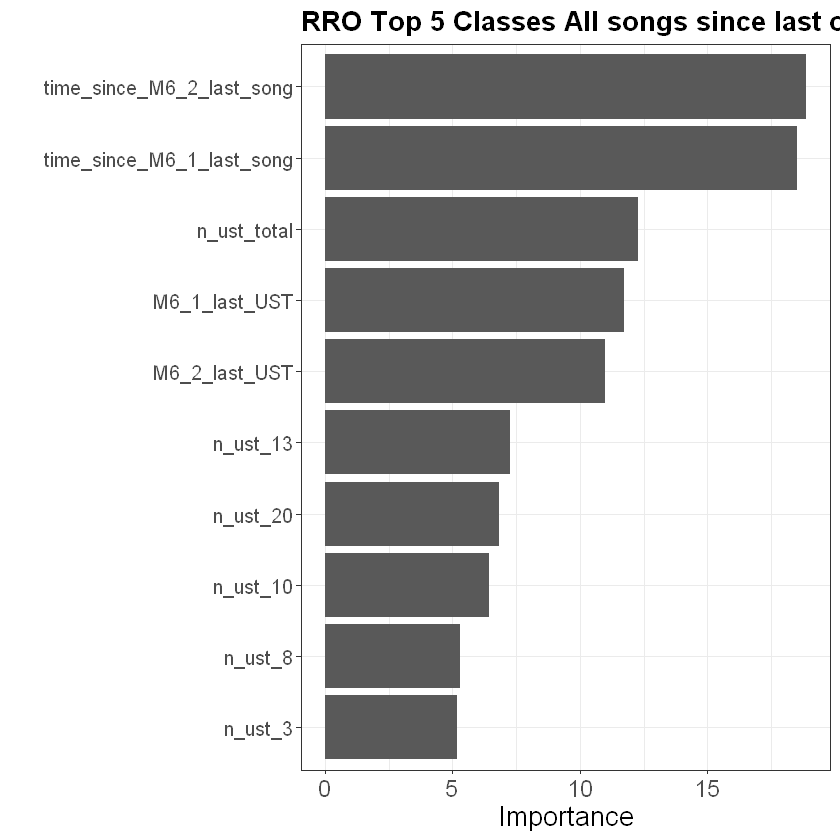

TbTbLg 4 


Saving 6.67 x 6.67 in image


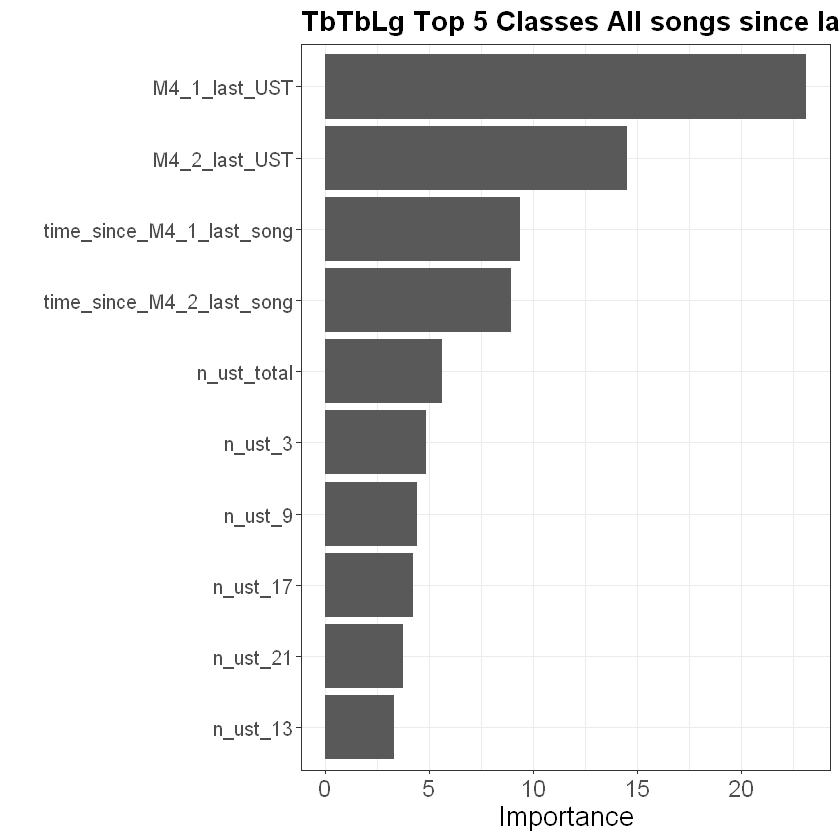

TbWY 1 


Saving 6.67 x 6.67 in image


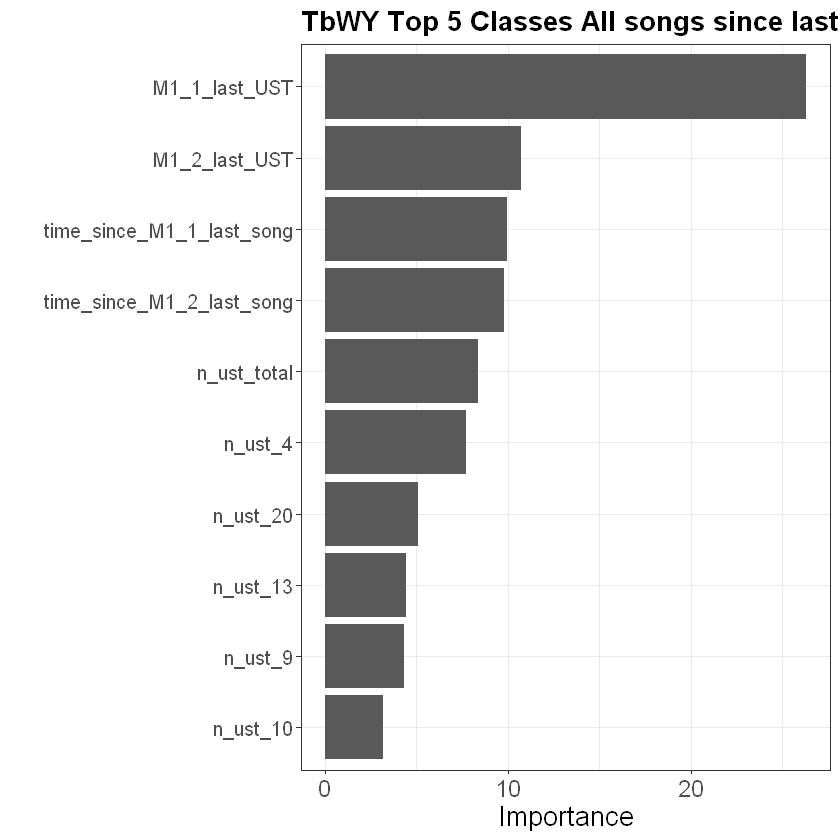

WLpTb 4 


Saving 6.67 x 6.67 in image


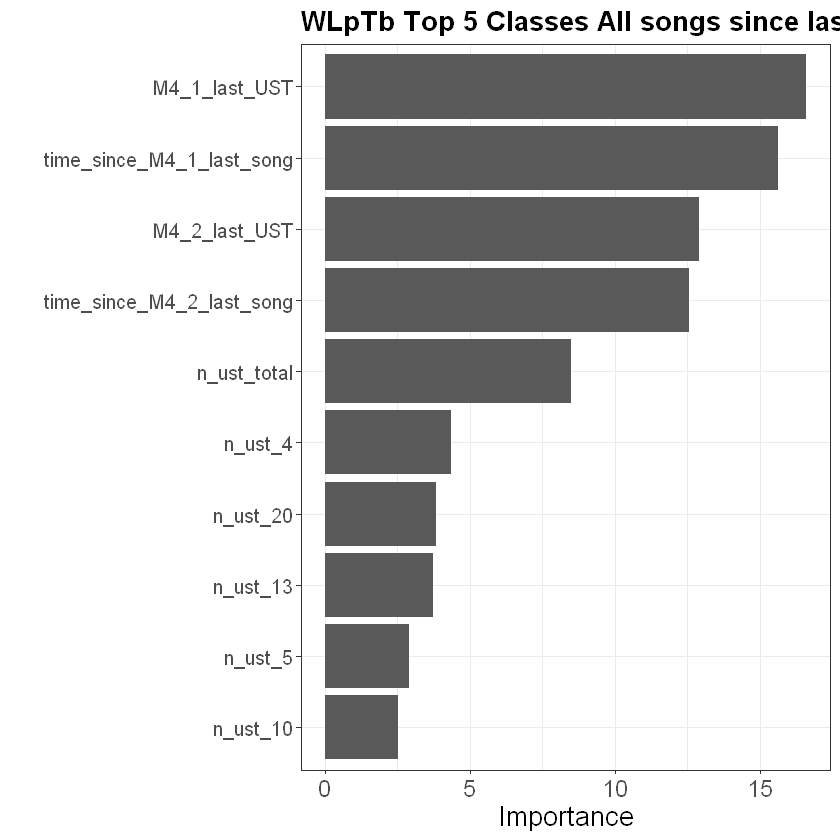

YKY 3 


Saving 6.67 x 6.67 in image


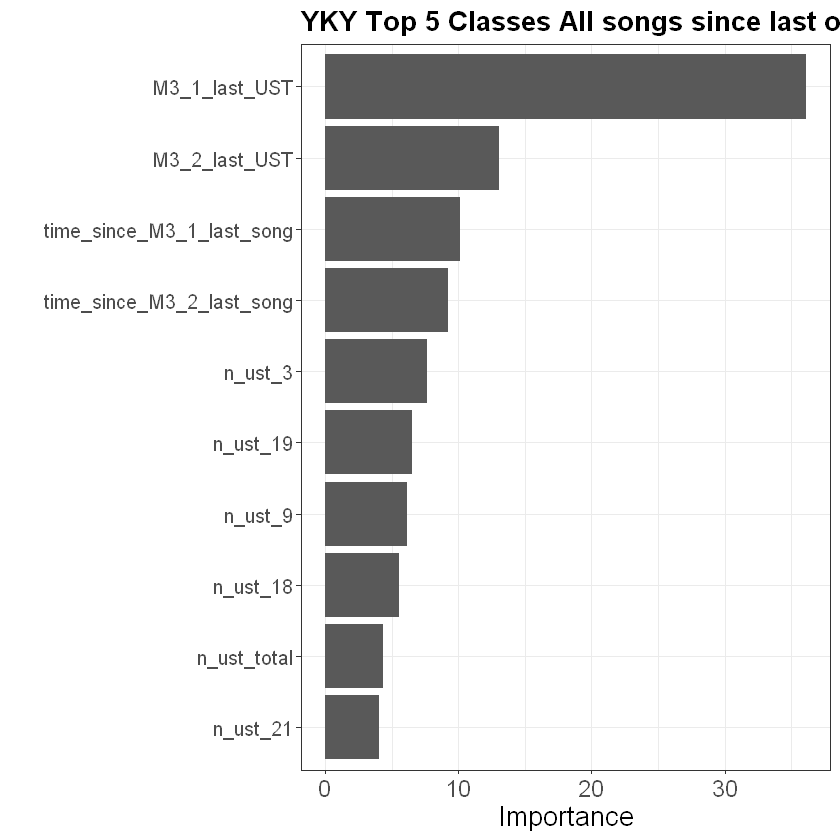

In [13]:
for (id in focal_ids) {
  model <- models_list[[id]]
  male_number <- focal_males %>% filter(ID == id) %>% pull(male_number)
  neighbourhood <- focal_males %>% filter(ID == id) %>% pull(neighbourhood)
  importance_chart <- model %>% extract_fit_engine() %>% vip(num_features=10) +
    labs(title=paste(id, MODEL_TYPE, male_number, neighbourhood)) +
    theme_bw() + # Starting with a clean theme
    theme(
      axis.text.x = element_text(size = 14),       # X-axis tick labels
      axis.text.y = element_text(size = 12),       # Y-axis tick labels
      axis.title.x = element_text(size = 16),      # X-axis title
      axis.title.y = element_text(size = 16),      # Y-axis title
      plot.title = element_text(size = 16, face = "bold"), # Main plot title
      legend.text = element_text(size = 12),       # Legend labels
      legend.title = element_text(size = 14)       # Legend title
    )
  print(importance_chart)
  cat(id, male_number, '\n')
  ggsave(paste(MODEL_TYPE, id, "importance.png"), plot=importance_chart)
}


In [14]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
# Return the accuracy, precision, and recall of our model

all_test_accuracies = tibble()
all_song_accuracies = tibble()

for (id in focal_ids) {
    View(id)
    test_data <- testing_datasets[[id]]
    model <- models_list[[id]]
    test_predictions <- model %>% predict(test_data) %>%
        bind_cols(test_data)
    test_accuracy <- test_predictions %>% 
        metrics(truth = UST, estimate = .pred_class) %>% 
        filter(.metric == "accuracy") %>% 
        rename(estimated_accuracy = .estimate) %>%
        mutate(ID = id, model=MODEL_TYPE) %>%
        select(ID, estimated_accuracy, model)
        # TODO: Add other features such as repertoire size, size of territory, neighbourhood
        #%>% pull(.estimate) %>% round(3)
    View(test_accuracy)
    all_test_accuracies <- all_test_accuracies %>% bind_rows(test_accuracy)

    test_song_accuracies <- test_predictions %>% group_by(UST) %>% 
        metrics(truth = UST, estimate = .pred_class) %>% 
        filter(.metric == "accuracy") %>% 
        arrange(desc(.estimate)) %>% 
        mutate(ID = id, model=MODEL_TYPE) %>%
        select(ID, UST, .estimate, model) %>% 
        rename(estimated_accuracy = .estimate) %>%
        left_join(n_ust %>% select(UST, n), by = "UST")
    View(test_song_accuracies)
    all_song_accuracies <- all_song_accuracies %>% bind_rows(test_song_accuracies)

    # View(test_predictions %>% group_by(UST) %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate))) # Precision = correct positive predictions / total positive predictions
    # View(test_predictions %>% group_by(UST) %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate))) # Recall = correct positive predictions / total positive test set observations

    confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
    print(confusion_matrix)
}

[1] "DgTbO"

ID,estimated_accuracy,model
<chr>,<dbl>,<chr>
DgTbO,0.3682927,Top 5 Classes All songs since last own song


ID,UST,estimated_accuracy,model,n
<chr>,<fct>,<dbl>,<chr>,<int>
DgTbO,33,0.5213675,Top 5 Classes All songs since last own song,NA
DgTbO,20,0.4935065,Top 5 Classes All songs since last own song,NA
DgTbO,7,0.3030303,Top 5 Classes All songs since last own song,NA
DgTbO,10,0.2441860,Top 5 Classes All songs since last own song,NA
DgTbO,8,0.1718750,Top 5 Classes All songs since last own song,NA


[1] "KLgK"

ID,estimated_accuracy,model
<chr>,<dbl>,<chr>
KLgK,0.4756098,Top 5 Classes All songs since last own song


ID,UST,estimated_accuracy,model,n
<chr>,<fct>,<dbl>,<chr>,<int>
KLgK,0,0.7500000,Top 5 Classes All songs since last own song,NA
KLgK,13,0.6428571,Top 5 Classes All songs since last own song,NA
KLgK,4,0.5217391,Top 5 Classes All songs since last own song,NA
KLgK,8,0.4666667,Top 5 Classes All songs since last own song,NA
KLgK,10,0.1111111,Top 5 Classes All songs since last own song,NA


... (24 outputs left out)

[1] "YKY"

ID,estimated_accuracy,model
<chr>,<dbl>,<chr>
YKY,0.6589147,Top 5 Classes All songs since last own song


ID,UST,estimated_accuracy,model,n
<chr>,<fct>,<dbl>,<chr>,<int>
YKY,21,0.7333333,Top 5 Classes All songs since last own song,69
YKY,1,0.7200000,Top 5 Classes All songs since last own song,56
YKY,166,0.7200000,Top 5 Classes All songs since last own song,56
YKY,9,0.6400000,Top 5 Classes All songs since last own song,57
YKY,27,0.4583333,Top 5 Classes All songs since last own song,54


          Truth
Prediction  7  8 10 20 33
        7  20 10 14  7  8
        8   2 11 11  6 10
        10 13 11 21  9 19
        20  7  8 15 38 19
        33 24 24 25 17 61
          Truth
Prediction  0  4  8 10 13
        0   9  0  0  0  0
        4   1 12  5  5  3
        8   0  5  7  5  0
        10  1  3  3  2  2
        13  1  3  0  6  9
          Truth
Prediction  9 20 28 104 106
       9   32  6  5   2   0
       20   4 18  3   2   1
       28   0  3 20   4   7
       104  3  0  1  14   0
       106  2  0  1   1  13
          Truth
Prediction  3  8  9 10 29
        3  11  7  4  4  2
        8   9 10  8  3  5
        9   2  5 16  8  5
        10  6  5  4  8  3
        29  2  3  2  2 10
          Truth
Prediction 26 34 125 127 130
       26  26 11   5   5   3
       34   8 38   0   4   4
       125  1  1  13   1   0
       127  2  4   3  15   4
       130  4  1   1   5  19
          Truth
Prediction  3  8  9 19 21
        3   9  4  3  2  1
        8   3 13 12  1  3
        9   1  0

In [15]:
filename <- paste0("data/results/", MODEL_TYPE, "_test_accuracies.csv")
print(filename)
write_csv(all_test_accuracies, filename)

filename <- paste0("data/results/", MODEL_TYPE, "_song_accuracies.csv")
print(filename)
write_csv(all_song_accuracies, filename)

[1] "data/results/Top 5 Classes All songs since last own song_test_accuracies.csv"
[1] "data/results/Top 5 Classes All songs since last own song_song_accuracies.csv"


Visualizing results

In [17]:
test_accuracies <- list()
song_accuracies <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies <- append(test_accuracies, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies <- append(song_accuracies, list("{file}" = read_csv(file)))
    }
}

test_accuracies <- bind_rows(test_accuracies)
song_accuracies <- bind_rows(song_accuracies)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs in last 60s_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs in last 60s_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs since last own song_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (34 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Top 5 Classes All songs since last own song_song_accuracies.csv"


Rows: 55 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Top 5 Classes All songs since last own song_test_accuracies.csv"


Rows: 11 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


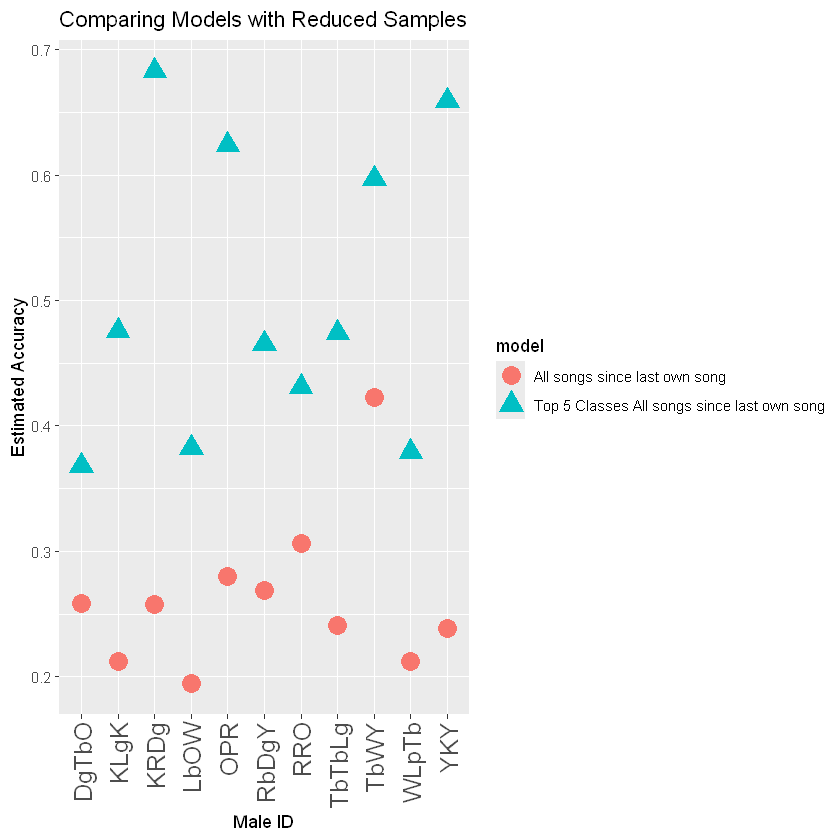

In [ ]:
plot <- ggplot(data = test_accuracies %>% filter(model %in% c("All songs since last own song", "Top 5 Classes All songs since last own song", "Song types N greater than 30 All songs since last own song")), aes(x=ID, y=estimated_accuracy, color=model, shape=model)) +
    geom_point(size=5) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size=15)) + # making x axis labels vertical
    labs(x="Male ID", y="Estimated Accuracy", title="Comparing Models with Reduced Samples")
print(plot)